# 01 — Exploratory Data Analysis (EDA)

**Dataset:** Multiclass Social Media Dataset for Mental Health and Emotion Classification ([Mendeley Data DOI: 10.17632/rw57wvg6z2.2](https://data.mendeley.com/datasets/rw57wvg6z2/2))

This notebook inspects schema, nulls, duplicates, class imbalance, text length skew, and social-media noise/artifacts before any modeling.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
from IPython.display import Image, display
from src.data_loader import run_eda
from src.preprocess import clean_social_text, select_before_after_examples
from src.utils import RESULTS_DIR, set_seed

set_seed()


In [2]:
df, eda_summary = run_eda()
print('Audit counts:', eda_summary['audit_counts'])
print('Imbalance ratio (max/min):', eda_summary['imbalance_ratio'])
pd.DataFrame({'Count': eda_summary['class_counts'], 'Share (%)': eda_summary['class_percentages']})

19:30:50 | INFO    | src.data_loader | Loaded raw dataset from Mental_Health_6Class_Final_Cleaned.csv: 42518 rows, columns=['Unnamed: 0', 'Text', 'Emotion']


19:30:52 | INFO    | src.data_loader | Deduplication & null check complete: initial=42518 | nulls=0 | empty=0 | exact_dups=0 | norm_dups=11 | total_removed=11 | final=42507


19:31:14 | INFO    | src.data_loader | Generating EDA plots in C:\Users\mansi\OneDrive\Desktop\socialmediaexp\results ...


19:31:43 | INFO    | src.data_loader | EDA complete. Summary and 4 plots saved to C:\Users\mansi\OneDrive\Desktop\socialmediaexp\results.


Audit counts: {'rows_initial': 42518, 'nulls_removed': 0, 'empty_removed': 0, 'exact_dups_removed': 0, 'normalized_dups_removed': 11, 'total_removed': 11, 'rows_final': 42507}
Imbalance ratio (max/min): 2.06


,Count,Share (%)
Positive,9766,22.98
Neutral,7899,18.58
Anger,7121,16.75
Depression,6762,15.91
Sadness,6221,14.64
Anxiety,4738,11.15


In [3]:
pd.DataFrame(eda_summary['per_class_length']).T

,word_mean,word_median,word_max,char_mean,char_median
Positive,23.16,21.0,69.0,116.19,106.0
Neutral,17.68,10.0,213.0,91.55,50.0
Anger,21.40,19.0,68.0,108.37,97.0
Depression,176.41,122.0,1500.0,890.49,617.0
Sadness,20.37,18.0,65.0,103.47,91.0
Anxiety,24.27,23.0,66.0,124.50,115.0


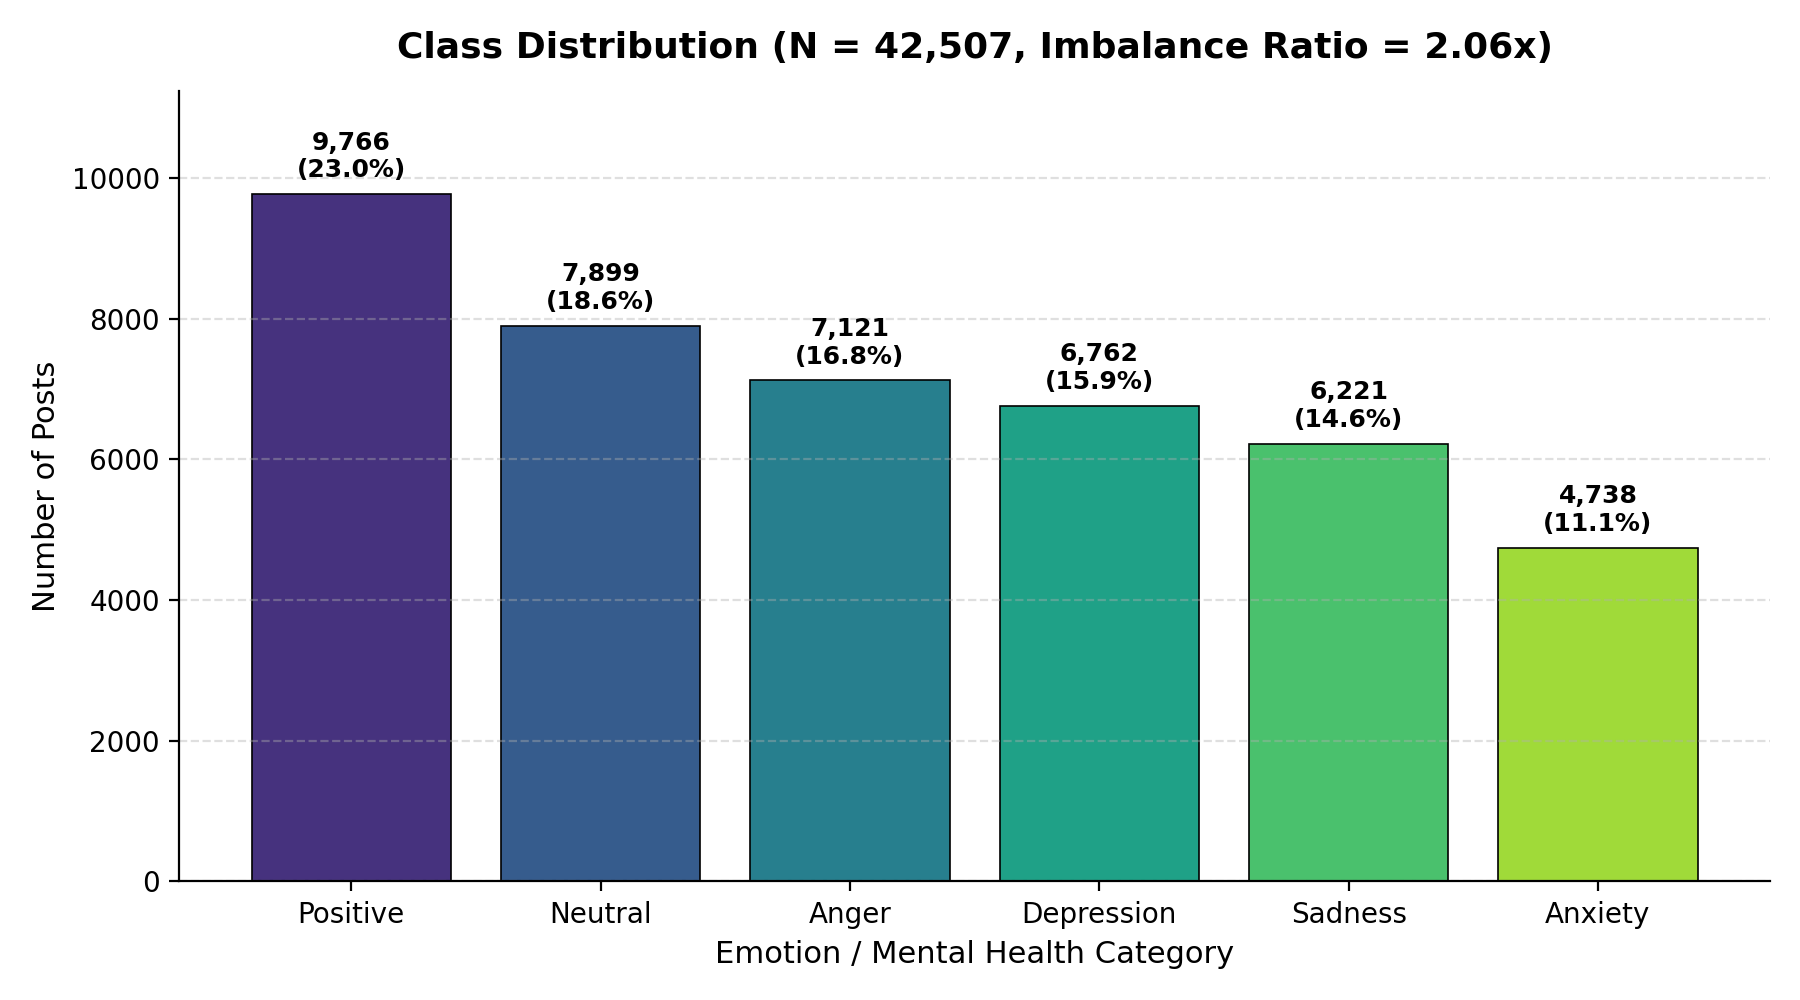

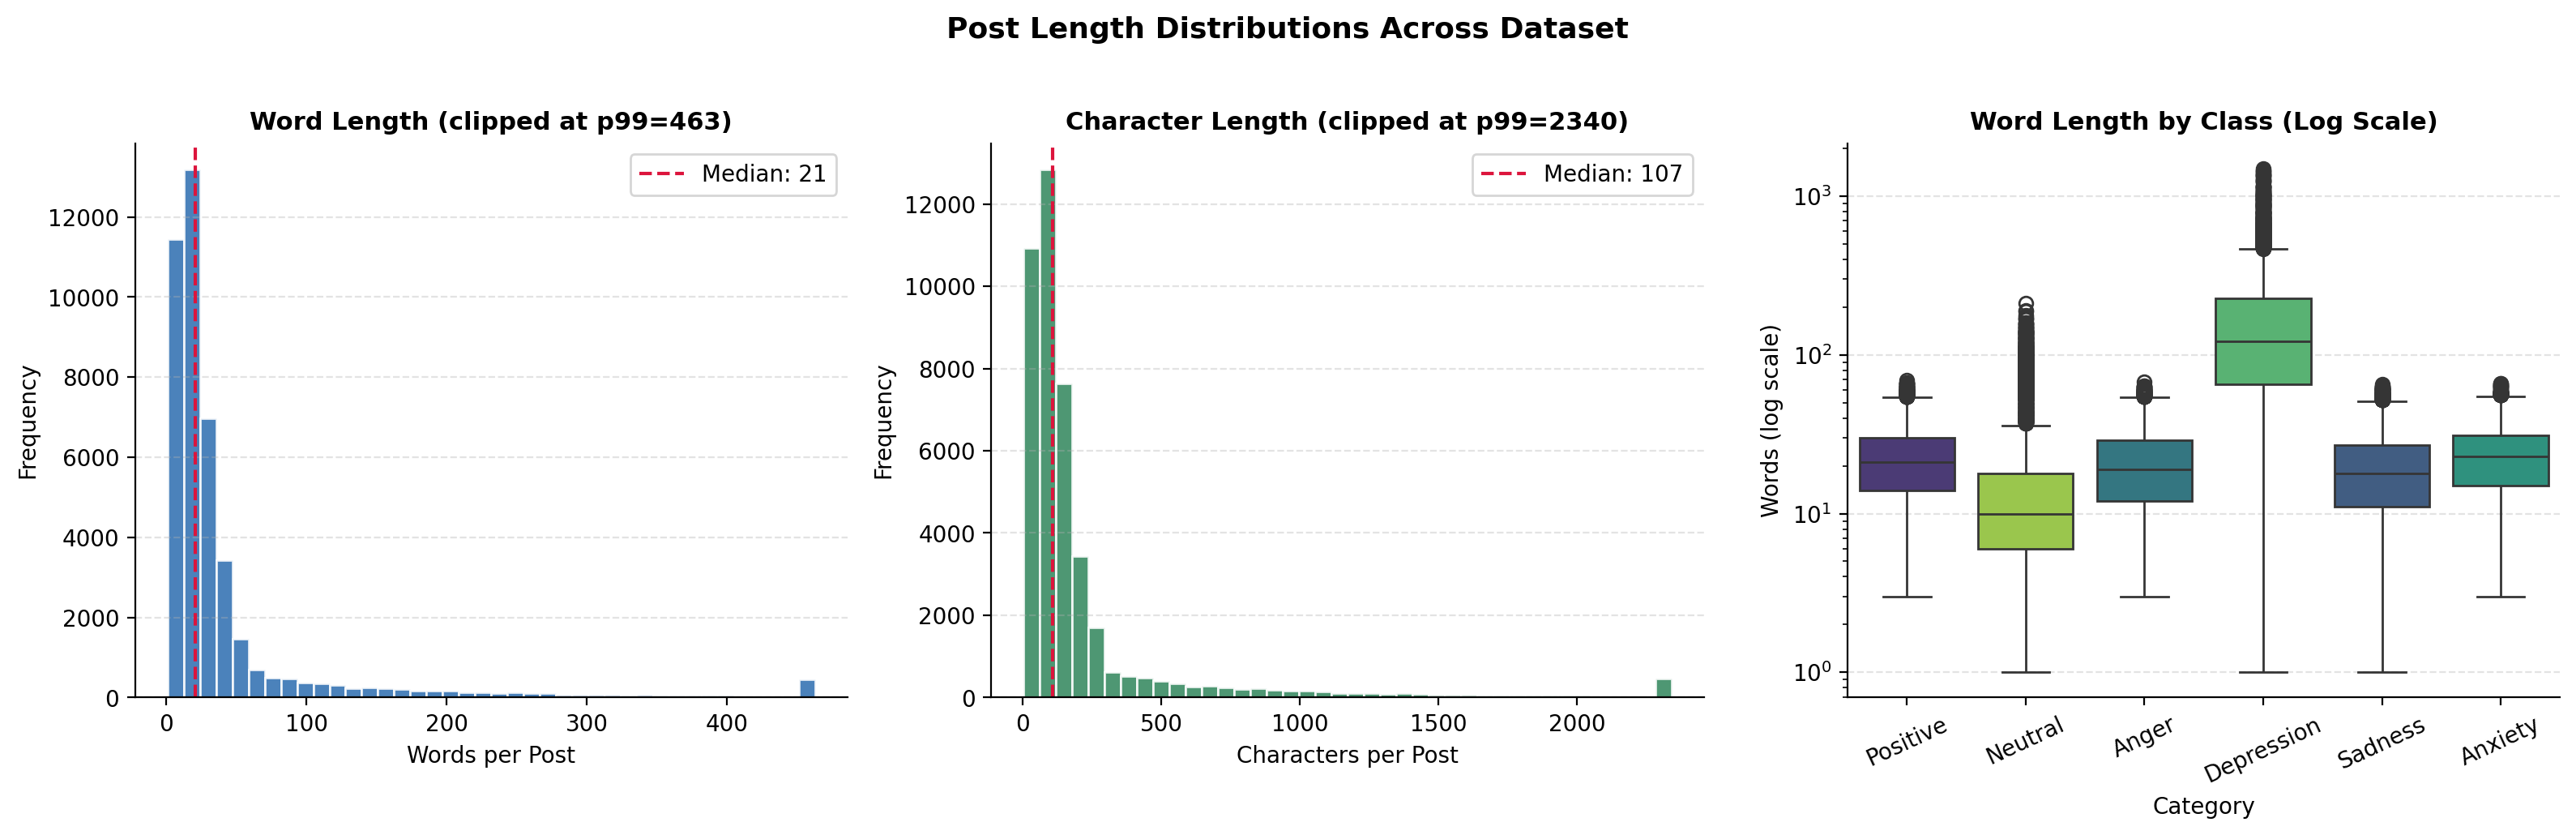

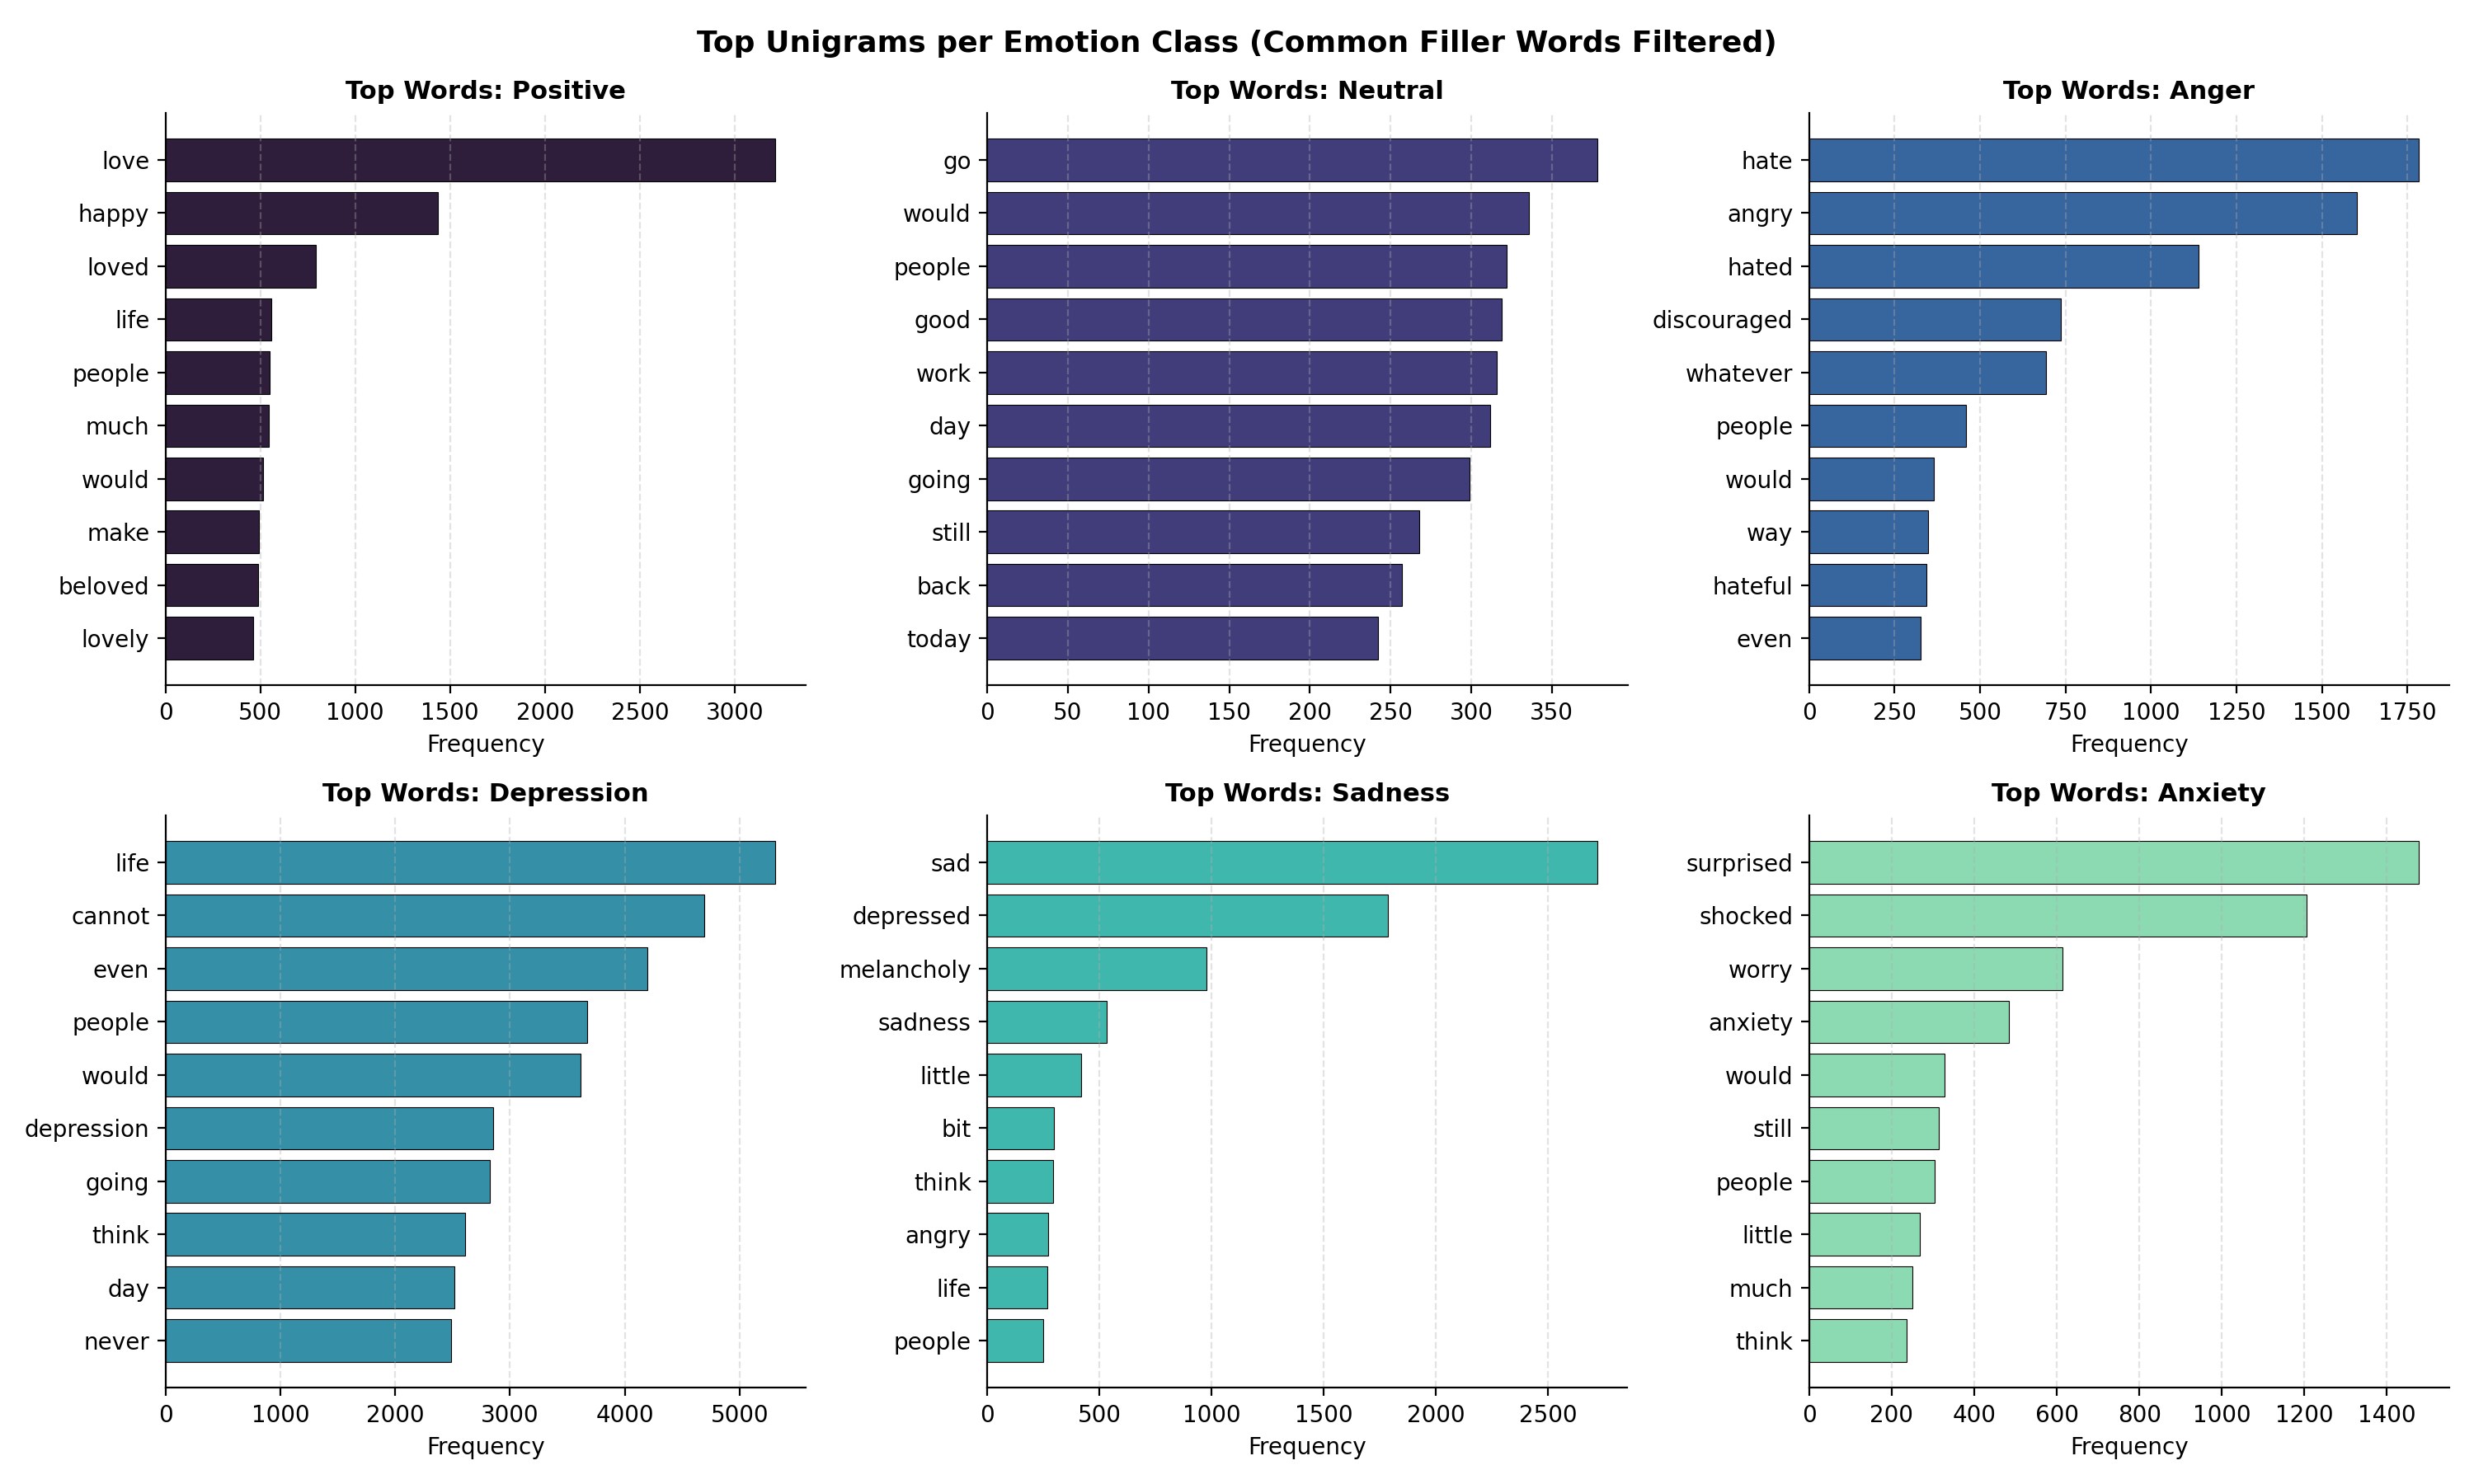

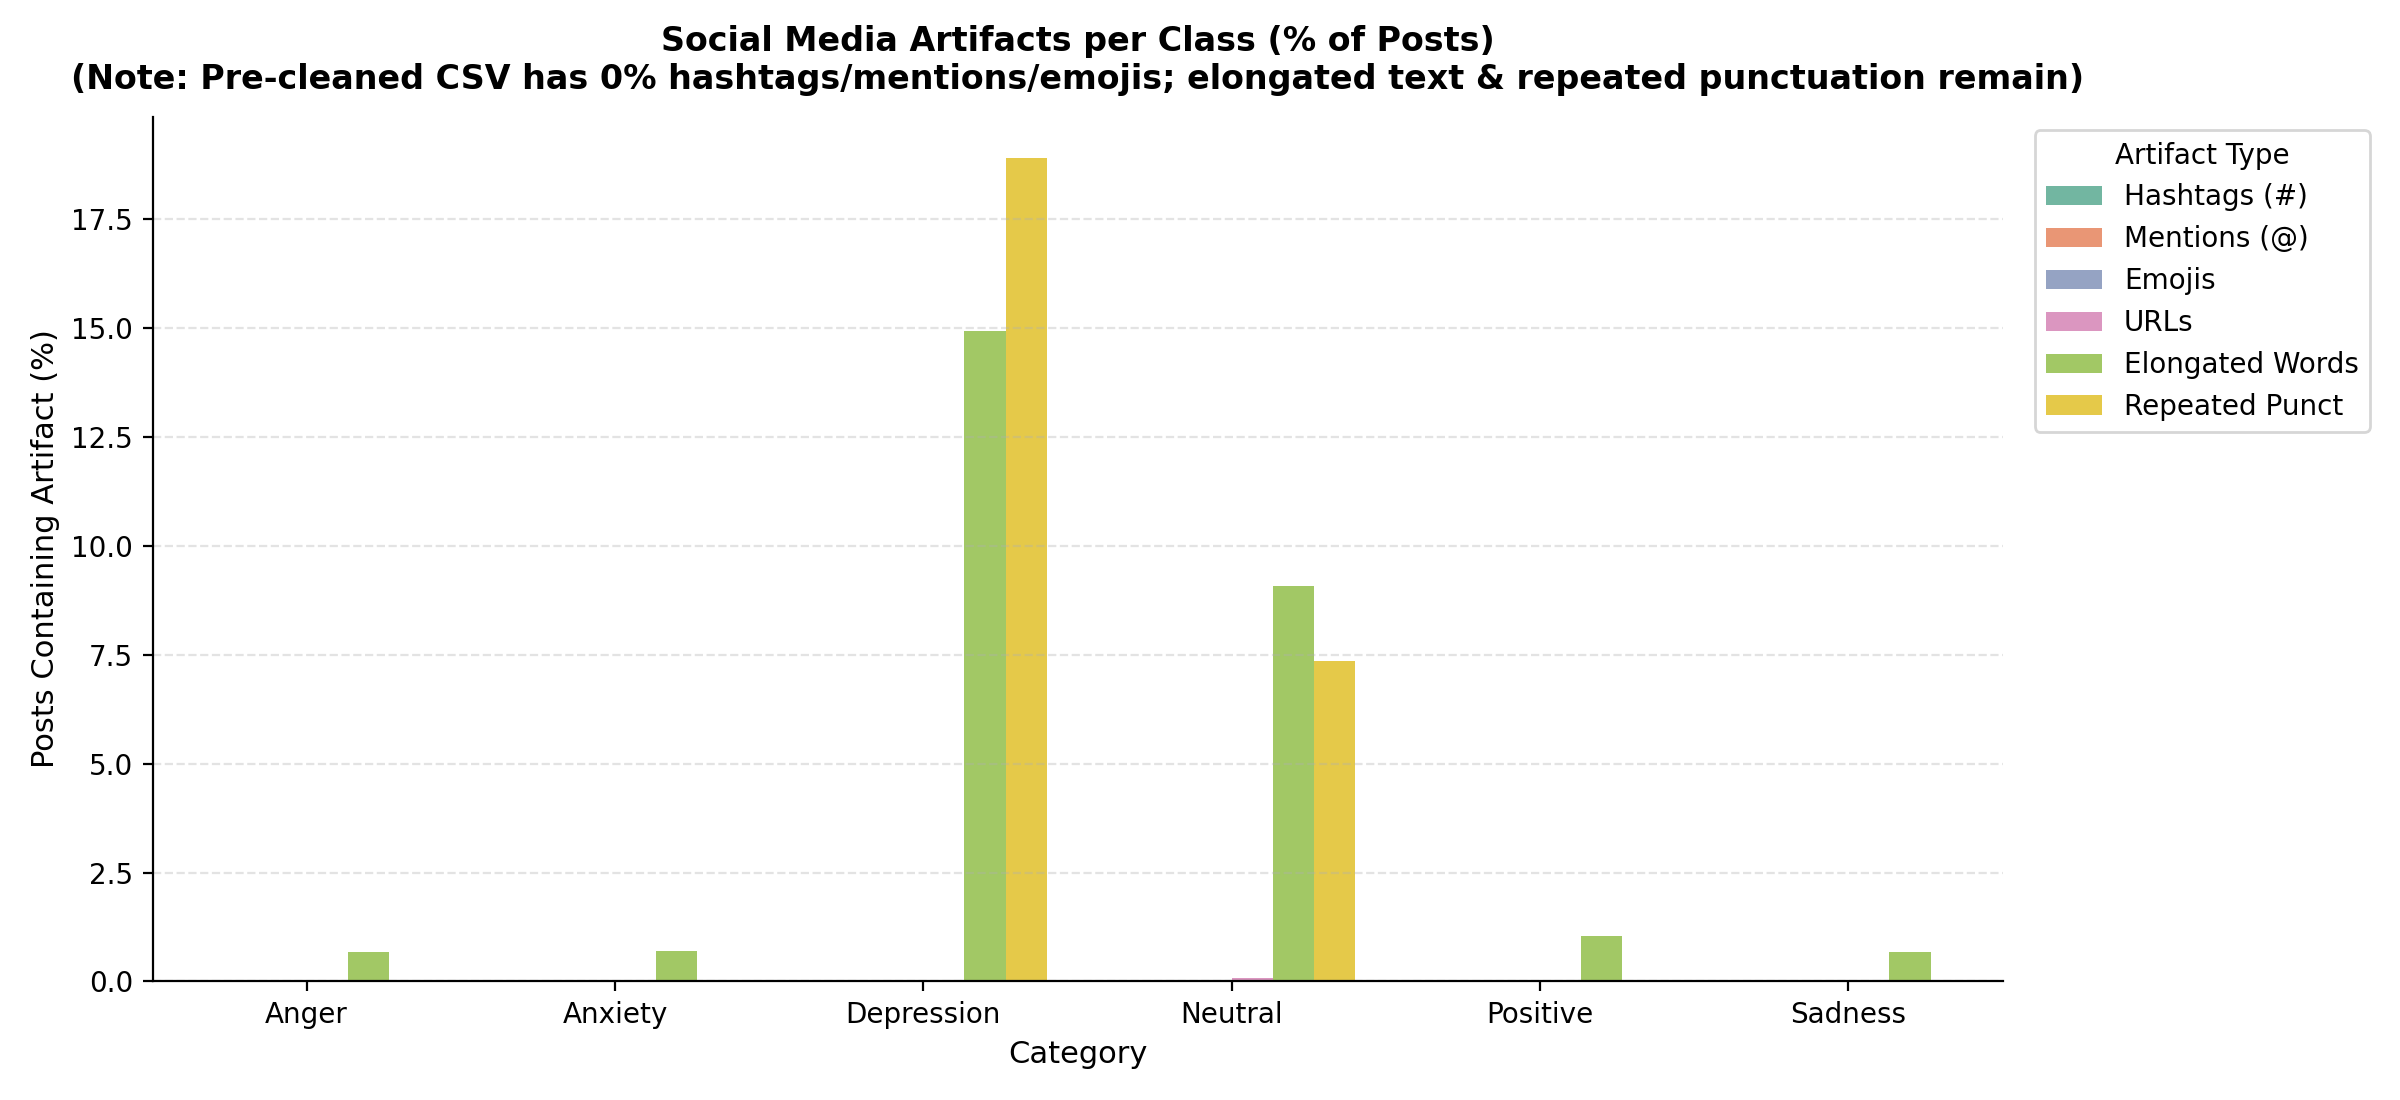

In [4]:
for fname in [
    'eda_class_distribution.png',
    'eda_length_distribution.png',
    'eda_top_words_per_class.png',
    'eda_social_artifacts_per_class.png',
]:
    display(Image(filename=str(RESULTS_DIR / fname)))

## Preprocessing Preview (5 Raw vs. Cleaned Examples)

In [5]:
df['clean_text'] = df['Text'].apply(clean_social_text)
examples = select_before_after_examples(df, n=5)
pd.DataFrame(examples)

,category,label,raw,cleaned
0,URL + Noise,Neutral,Cool httpwww.onlinemarktplatz.de14177twitterfi...,cool <URL>
1,Elongated / Repeated Punct,Positive,i feels unhappy audience can t accept sniper s...,feel unhappy audience accept sniper standoff k...
2,Contraction + Negation,Sadness,i can go when im feeling angry or tormented or...,go feeling angry tormented conflicted sad not ...
3,Long Mental Health Post,Anger,one day i had sunned my favourite shirt and wa...,one day sunned favourite shirt putting back wa...
4,Short Emotion Post,Anxiety,im feeling bummed but also shocked because it ...,feeling bummed also shocked really snuck
